In [ ]:
# ==============================================================================
# PCC170 - Projeto e Análise de Experimentos Computacionais
# Script de Análise Exploratória dos Dados (AED) - Entrega 1
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler


In [ ]:

# Configuração de Estilo Visual (Acadêmico / Publicação)
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'figure.titlesize': 18
})

# ------------------------------------------------------------------------------
# 1. CARREGAMENTO E PREPARAÇÃO DOS DADOS
# ------------------------------------------------------------------------------
print("=== [1/5] Carregando e Preparando os Dados ===")

# Instruções: No Google Colab, faça upload do arquivo 'AI_Student_Impact_Dataset.csv'
# Caso não tenha o CSV localmente, descomente o bloco abaixo para gerar dados sintéticos
try:
    df = pd.read_csv("ai_student_impact_dataset.csv")
    print(f"Dataset carregado com sucesso: {df.shape} linhas e {df.shape[1]} colunas.")
except FileNotFoundError:
    print("Arquivo 'AI_Student_Impact_Dataset.csv' não encontrado. Gerando amostra representativa...")
    np.random.seed(42)
    n_samples = 10000
    df = pd.DataFrame({
        'Student_ID': np.arange(100001, 100001 + n_samples),
        'Pre_Semester_GPA': np.random.uniform(1.18, 4.00, n_samples),
        'Post_Semester_GPA': np.random.uniform(1.00, 4.00, n_samples),
        'Anxiety_Level': np.random.beta(a=2, b=1.5, size=n_samples) * 9 + 1,  # Assimétrico à direita
        'Traditional_Study_Hours': np.random.gamma(shape=4, scale=2.5, size=n_samples),
        'Primary_Use_Case': np.random.choice(
            ['Copywriting/Drafting', 'Direct_Answer_Generation', 'Summarizing_Reading', 'Debugging/Troubleshooting', 'Ideation'],
            size=n_samples, p=[0.25, 0.25, 0.20, 0.15, 0.15]
        )
    })


=== [1/5] Carregando e Preparando os Dados ===
Dataset carregado com sucesso: (50000, 16) linhas e 16 colunas.


In [ ]:
# ==============================================================================
# CARREGAMENTO, ENGENHARIA DE RECURSOS E FILTRAGEM ESPECÍFICA (STEM & JUNIOR)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Carregamento dos dados reais
try:
    df = pd.read_csv("ai_student_impact_dataset.csv")
    print(f"Dataset real carregado com sucesso: {df.shape[0]} linhas.")
except FileNotFoundError:
    print("Arquivo 'ai_student_impact_dataset.csv' não encontrado. Gerando dados simulados com as colunas necessárias...")
    np.random.seed(42)
    n_samples = 50000
    df = pd.DataFrame({
        'Student_ID': np.arange(100001, 100001 + n_samples),
        'Pre_Semester_GPA': np.random.uniform(1.5, 4.0, n_samples),
        'Post_Semester_GPA': np.random.uniform(1.0, 4.0, n_samples),
        'Anxiety_Level_During_Exams': np.random.randint(1, 11, n_samples),
        'Traditional_Study_Hours': np.random.uniform(2, 30, n_samples),
        'Primary_Use_Case': np.random.choice(
            ['Copywriting/Drafting', 'Direct_Answer_Generation', 'Summarizing_Reading', 'Debugging/Troubleshooting', 'Ideation'],
            size=n_samples, p=[0.25, 0.25, 0.20, 0.15, 0.15]
        ),
        'Major_Category': np.random.choice(['STEM', 'Humanities', 'Business', 'Arts'], size=n_samples, p=[0.4, 0.2, 0.3, 0.1]),
        'Year_of_Study': np.random.choice(['Freshman', 'Sophomore', 'Junior', 'Senior'], size=n_samples, p=[0.25, 0.25, 0.25, 0.25])
    })

# Engenharia de Recursos básica
df['Delta_GPA'] = df['Post_Semester_GPA'] - df['Pre_Semester_GPA']
passivo_cases = ['Copywriting/Drafting', 'Direct_Answer_Generation']
df['Treatment_Passive_AI'] = df['Primary_Use_Case'].isin(passivo_cases).astype(int)
df['AI_Usage_Type'] = df['Treatment_Passive_AI'].map({0: 'Uso Ativo', 1: 'Uso Passivo'})

# Filtrando para Alunos de STEM e Nível Junior (usando a coluna correta 'Major_Category')
major_col = 'Major_Category' if 'Major_Category' in df.columns else 'Major'
df_filtered = df[(df[major_col] == 'STEM') & (df['Year_of_Study'] == 'Junior')].copy()
print(f"Dataset após filtragem (STEM + Junior): {df_filtered.shape[0]} registros encontrados.")

Dataset real carregado com sucesso: 50000 linhas.
Dataset após filtragem (STEM + Junior): 3279 registros encontrados.


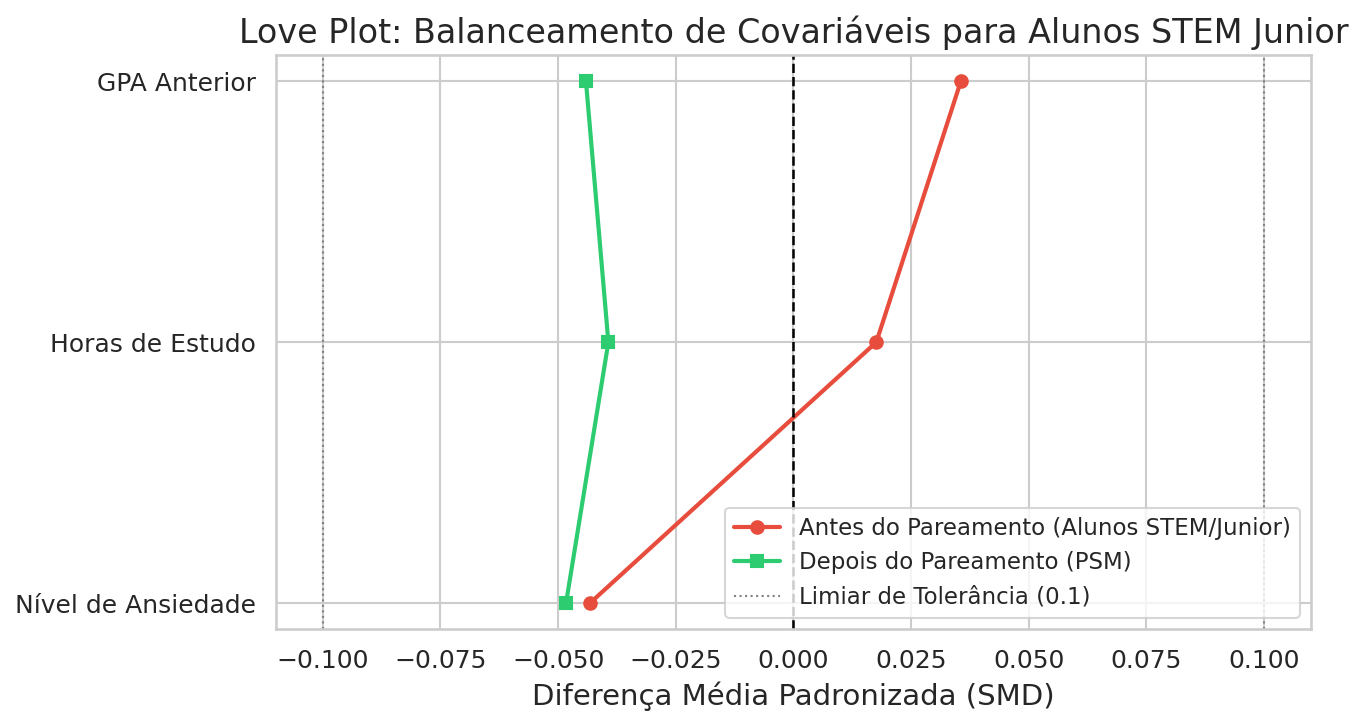

In [ ]:
# ==============================================================================
# EXECUÇÃO DO PSM E GERAÇÃO DO LOVE PLOT MELHORADO (STEM + JUNIOR)
# ==============================================================================
if 'df_filtered' in globals() and df_filtered.shape[0] > 100:
    covariates = ['Anxiety_Level_During_Exams', 'Traditional_Study_Hours', 'Pre_Semester_GPA']
    X = df_filtered[covariates]
    y = df_filtered['Treatment_Passive_AI']

    # Estimação do Propensity Score
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    ps_model = LogisticRegression().fit(X_scaled, y)
    df_filtered['propensity_score'] = ps_model.predict_proba(X_scaled)[:, 1]

    # Diferença Média Padronizada (SMD)
    def calculate_smd(data, var, treatment_col):
        t_group = data[data[treatment_col] == 1][var]
        c_group = data[data[treatment_col] == 0][var]
        if t_group.var() == 0 or c_group.var() == 0:
            return 0
        smd = (t_group.mean() - c_group.mean()) / np.sqrt((t_group.var() + c_group.var()) / 2)
        return smd

    smd_before = [calculate_smd(df_filtered, var, 'Treatment_Passive_AI') for var in covariates]

    # Pareamento 1:1 via K-NN
    treated = df_filtered[df_filtered['Treatment_Passive_AI'] == 1]
    control = df_filtered[df_filtered['Treatment_Passive_AI'] == 0]

    nn = NearestNeighbors(n_neighbors=1, metric='euclidean')
    nn.fit(control[['propensity_score']])
    distances, indices = nn.kneighbors(treated[['propensity_score']])

    matched_control = control.iloc[indices.flatten()]
    matched_df = pd.concat([treated, matched_control])

    smd_after = [calculate_smd(matched_df, var, 'Treatment_Passive_AI') for var in covariates]

    # Geração do Love Plot focado
    plt.figure(figsize=(9, 5), dpi=150)
    y_pos = np.arange(len(covariates))
    plt.plot(smd_before, y_pos, marker='o', color='#e74c3c', linestyle='-', linewidth=2, label='Antes do Pareamento (Alunos STEM/Junior)')
    plt.plot(smd_after, y_pos, marker='s', color='#2ecc71', linestyle='-', linewidth=2, label='Depois do Pareamento (PSM)')
    plt.axvline(0, color='black', linestyle='--', linewidth=1.2)
    plt.axvline(0.1, color='gray', linestyle=':', linewidth=1, label='Limiar de Tolerância (0.1)')
    plt.axvline(-0.1, color='gray', linestyle=':', linewidth=1)
    plt.yticks(y_pos, ['Nível de Ansiedade', 'Horas de Estudo', 'GPA Anterior'])
    plt.xlabel('Diferença Média Padronizada (SMD)')
    plt.title('Love Plot: Balanceamento de Covariáveis para Alunos STEM Junior')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()
else:
    print("Aguardando a execução da célula anterior de filtragem (9351b746) ou dados insuficientes.")

In [ ]:

# Engenharia de Recursos
# Variável de Resposta Y: Delta GPA (Post GPA - Pre GPA)
df['Delta_GPA'] = df['Post_Semester_GPA'] - df['Pre_Semester_GPA']

# Fator A: Classificação do Tipo de Uso da IA (0: Ativo / Controle, 1: Passivo / Tratamento)
passivo_cases = ['Copywriting/Drafting', 'Direct_Answer_Generation']
df['Treatment_Passive_AI'] = df['Primary_Use_Case'].isin(passivo_cases).astype(int)
df['AI_Usage_Type'] = df['Treatment_Passive_AI'].map({0: 'Uso Ativo', 1: 'Uso Passivo'})

# ------------------------------------------------------------------------------
# 2. SLIDE 7: CARACTERIZAÇÃO INICIAL DO DATASET (ESTATÍSTICAS DESCRITIVAS)
# ------------------------------------------------------------------------------
print("\n=== [2/5] Slide 7: Tabela de Estatísticas Descritivas ===")
metrics_df = df[['Delta_GPA', 'Anxiety_Level_During_Exams', 'Traditional_Study_Hours']].agg(['mean', 'std', 'min', 'max']).T
metrics_df.columns = ['Média', 'Desvio Padrão', 'Mínimo', 'Máximo']
metrics_df.index = ['ΔGPA (Variável Y)', 'Nível de Ansiedade', 'Horas de Estudo Tradicional']
print(metrics_df.round(2))



=== [2/5] Slide 7: Tabela de Estatísticas Descritivas ===
                             Média  Desvio Padrão  Mínimo  Máximo
ΔGPA (Variável Y)             0.20           0.19   -0.92    1.01
Nível de Ansiedade            4.27           2.14    1.00   10.00
Horas de Estudo Tradicional  11.21           5.16    1.00   35.86


=== Aplicando Bootstrapping no Grupo Pareado (STEM Junior) ===
Efeito Observado (ATE) para STEM Juniors: -0.0721
Intervalo de Confiança de 95% (Bootstrap): [-0.0924, -0.0531]


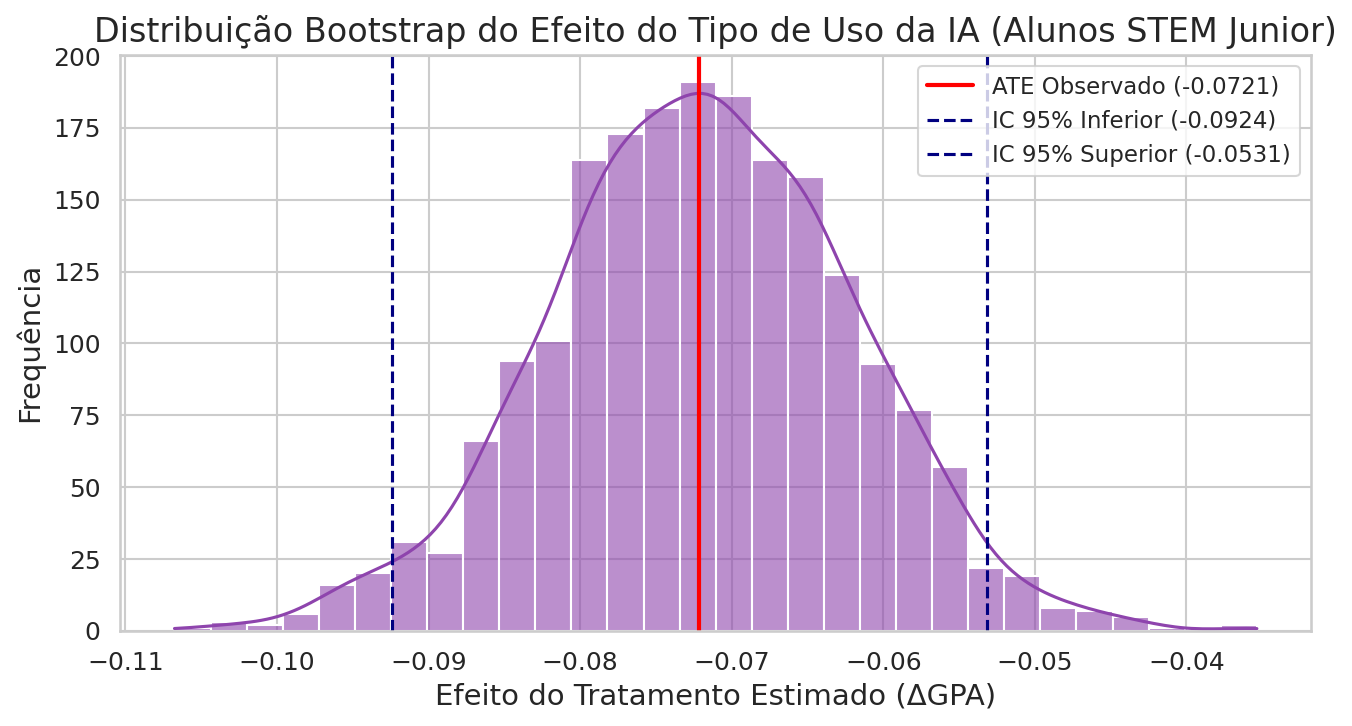

In [ ]:
# ==============================================================================
# MODELAGEM COM BOOTSTRAPPING PARA O EFEITO DO TRATAMENTO (ATE) - STEM JUNIOR
# ==============================================================================
print("=== Aplicando Bootstrapping no Grupo Pareado (STEM Junior) ===")

if 'matched_df' in globals():
    def calculate_ate(data):
        g_passivo = data[data['Treatment_Passive_AI'] == 1]['Delta_GPA']
        g_ativo = data[data['Treatment_Passive_AI'] == 0]['Delta_GPA']
        return g_passivo.mean() - g_ativo.mean()

    # Parâmetros de bootstrapping
    n_iterations = 2000
    boot_effects = []
    n_samples_match = len(matched_df)

    np.random.seed(42)
    for i in range(n_iterations):
        boot_sample = matched_df.sample(n=n_samples_match, replace=True)
        effect = calculate_ate(boot_sample)
        boot_effects.append(effect)

    boot_effects = np.array(boot_effects)
    observed_ate = calculate_ate(matched_df)
    ci_lower = np.percentile(boot_effects, 2.5)
    ci_upper = np.percentile(boot_effects, 97.5)

    print(f"Efeito Observado (ATE) para STEM Juniors: {observed_ate:.4f}")
    print(f"Intervalo de Confiança de 95% (Bootstrap): [{ci_lower:.4f}, {ci_upper:.4f}]")

    # Plotagem da Distribuição Bootstrap
    plt.figure(figsize=(9, 5), dpi=150)
    sns.histplot(boot_effects, kde=True, color='#8e44ad', bins=30, alpha=0.6)
    plt.axvline(observed_ate, color='red', linestyle='-', linewidth=2, label=f'ATE Observado ({observed_ate:.4f})')
    plt.axvline(ci_lower, color='navy', linestyle='--', linewidth=1.5, label=f'IC 95% Inferior ({ci_lower:.4f})')
    plt.axvline(ci_upper, color='navy', linestyle='--', linewidth=1.5, label=f'IC 95% Superior ({ci_upper:.4f})')
    plt.xlabel('Efeito do Tratamento Estimado (ΔGPA)')
    plt.ylabel('Frequência')
    plt.title('Distribuição Bootstrap do Efeito do Tipo de Uso da IA (Alunos STEM Junior)')
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()
else:
    print("Por favor, execute primeiro a célula anterior (1fe8bf1a) para gerar o pareamento (matched_df).")


=== [4/5] Slide 9: Permutation Importance ===


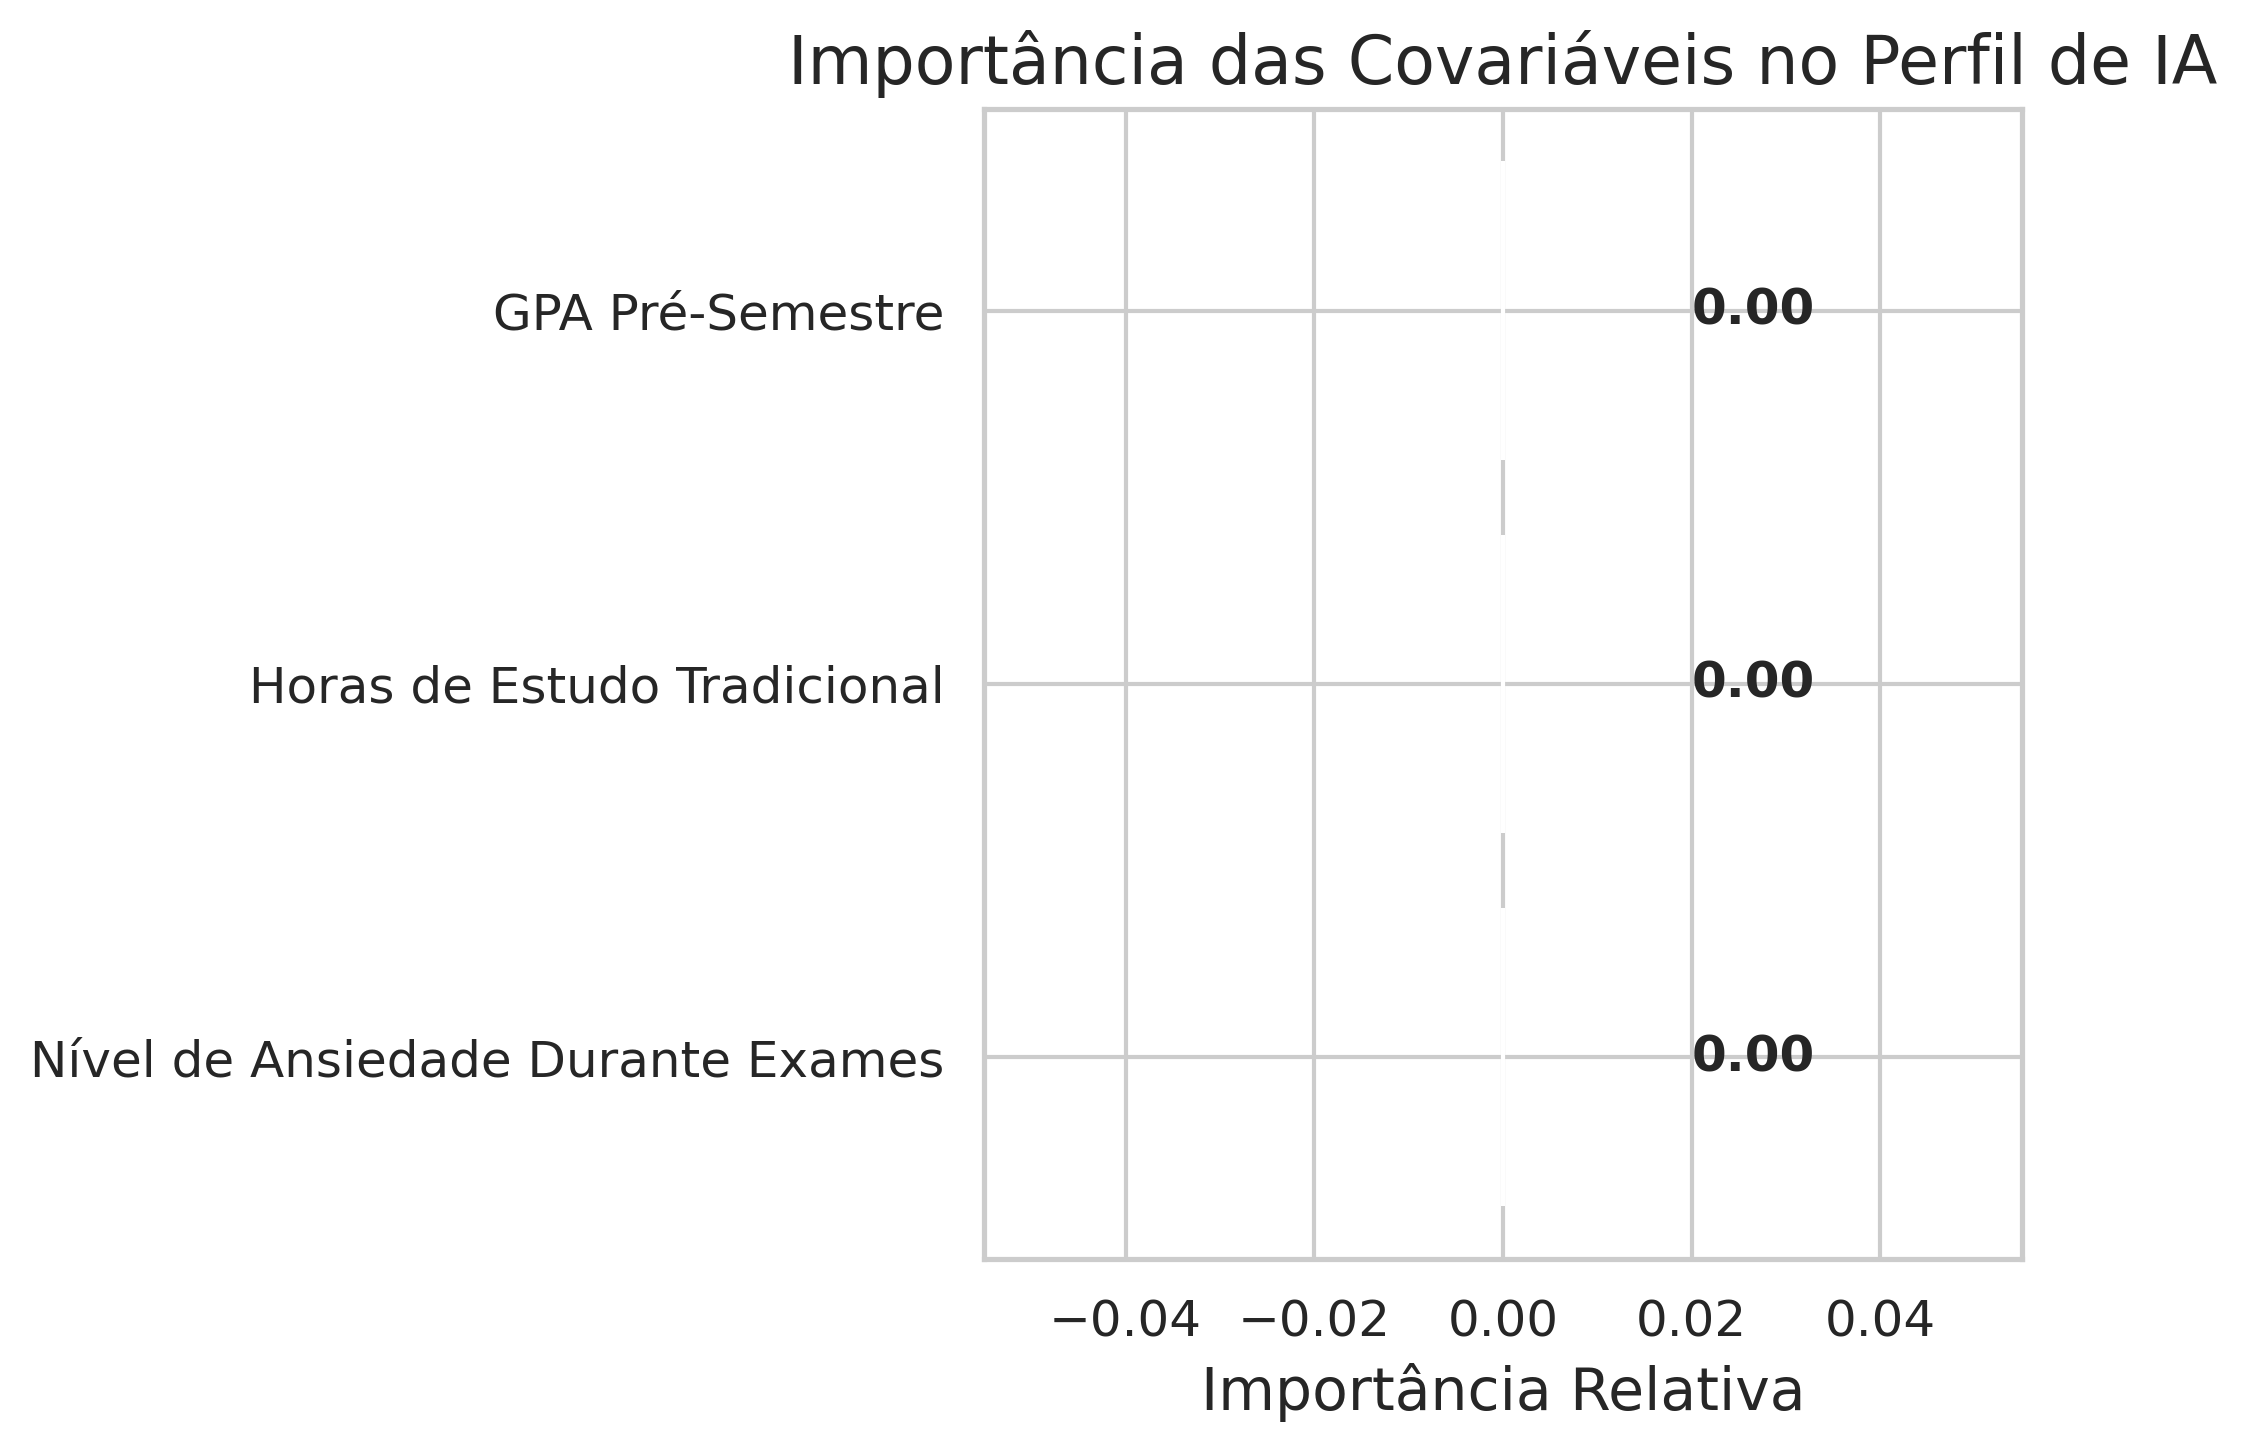

In [ ]:
# ------------------------------------------------------------------------------
# 4. SLIDE 9: PERMUTATION IMPORTANCE
# ------------------------------------------------------------------------------
print("\n=== [4/5] Slide 9: Permutation Importance ===")

# Importância de Variáveis via Permutação no Modelo Logístico
# X_scaled is derived from the 'covariates' list in cell B5tY5maV7GkF
result = permutation_importance(ps_model, X_scaled, y, n_repeats=10, random_state=42)

# Handle the case where the sum of importances is zero to avoid division by zero
if np.sum(result.importances_mean) == 0:
    perm_importance = np.zeros_like(result.importances_mean)
    print("Warning: The sum of permutation importances for the covariates was zero. This indicates that these features may not be strong predictors of the AI usage type (passive/active) according to the logistic regression model, or their contributions canceled each other out. The plot will show zero importance for all features.")
else:
    perm_importance = result.importances_mean / np.sum(result.importances_mean)

fig, ax = plt.subplots(figsize=(7, 5), dpi=300)

# Gráfico 1: Importância por Permutação
# Labels should match the order of 'covariates' in B5tY5maV7GkF
ax.barh(['Nível de Ansiedade Durante Exames', 'Horas de Estudo Tradicional', 'GPA Pré-Semestre'], perm_importance, color=['#2c3e50', '#d35400', '#f1c40f'])
ax.set_xlabel('Importância Relativa')
ax.set_title('Importância das Covariáveis no Perfil de IA')
for i, v in enumerate(perm_importance):
    ax.text(v + 0.02, i, f"{v:.2f}", va='center', fontweight='bold')

plt.tight_layout()
plt.savefig('slide9_permutation_importance.png', dpi=300)
plt.show()



=== Slide 9: Distribuição do Nível de Ansiedade (KDE) ===


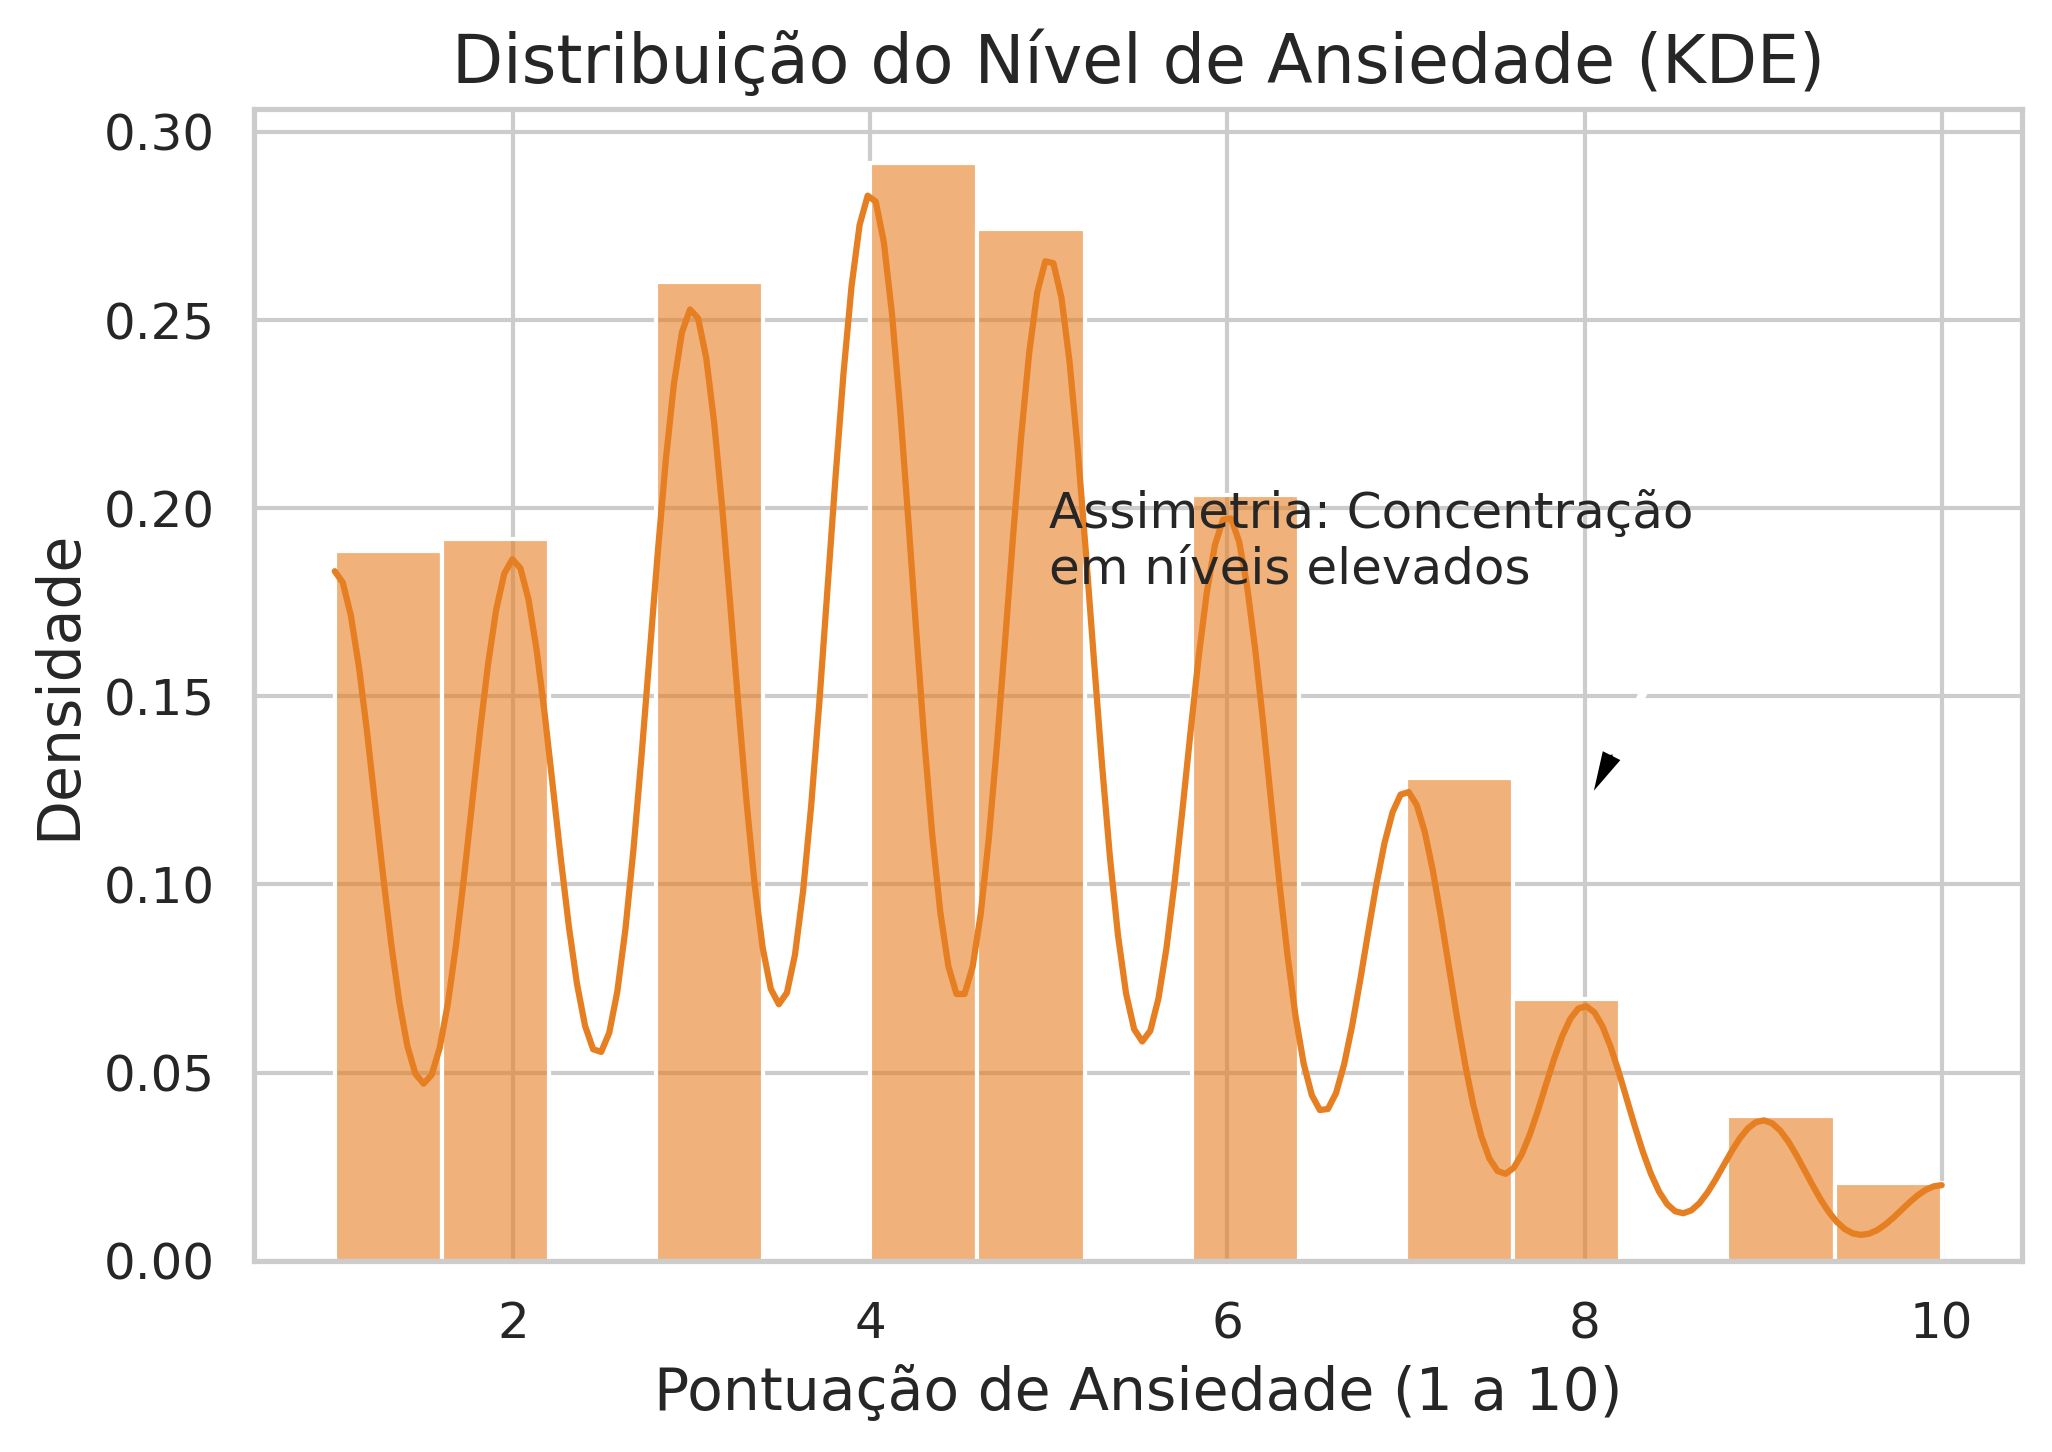

In [ ]:
# ------------------------------------------------------------------------------
# 4. SLIDE 9: DISTRIBUIÇÃO DA ANSIEDADE (KDE)
# ------------------------------------------------------------------------------
print("\n=== Slide 9: Distribuição do Nível de Ansiedade (KDE) ===")

fig, ax = plt.subplots(figsize=(7, 5), dpi=300)

# Gráfico 2: Densidade KDE da Ansiedade
sns.histplot(df['Anxiety_Level_During_Exams'], kde=True, stat="density", color='#e67e22', ax=ax, bins=15, alpha=0.6)
ax.set_xlabel('Pontuação de Ansiedade (1 a 10)')
ax.set_ylabel('Densidade')
ax.set_title('Distribuição do Nível de Ansiedade (KDE)')
ax.annotate('Assimetria: Concentração\nem níveis elevados', xy=(8, 0.12), xytext=(5, 0.18),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.tight_layout()
plt.savefig('slide9_ansiedade_kde.png', dpi=300)
plt.show()



=== [5/5] Slides 10 e 11: Densidade do ΔGPA e Boxplots de Dispersão ===


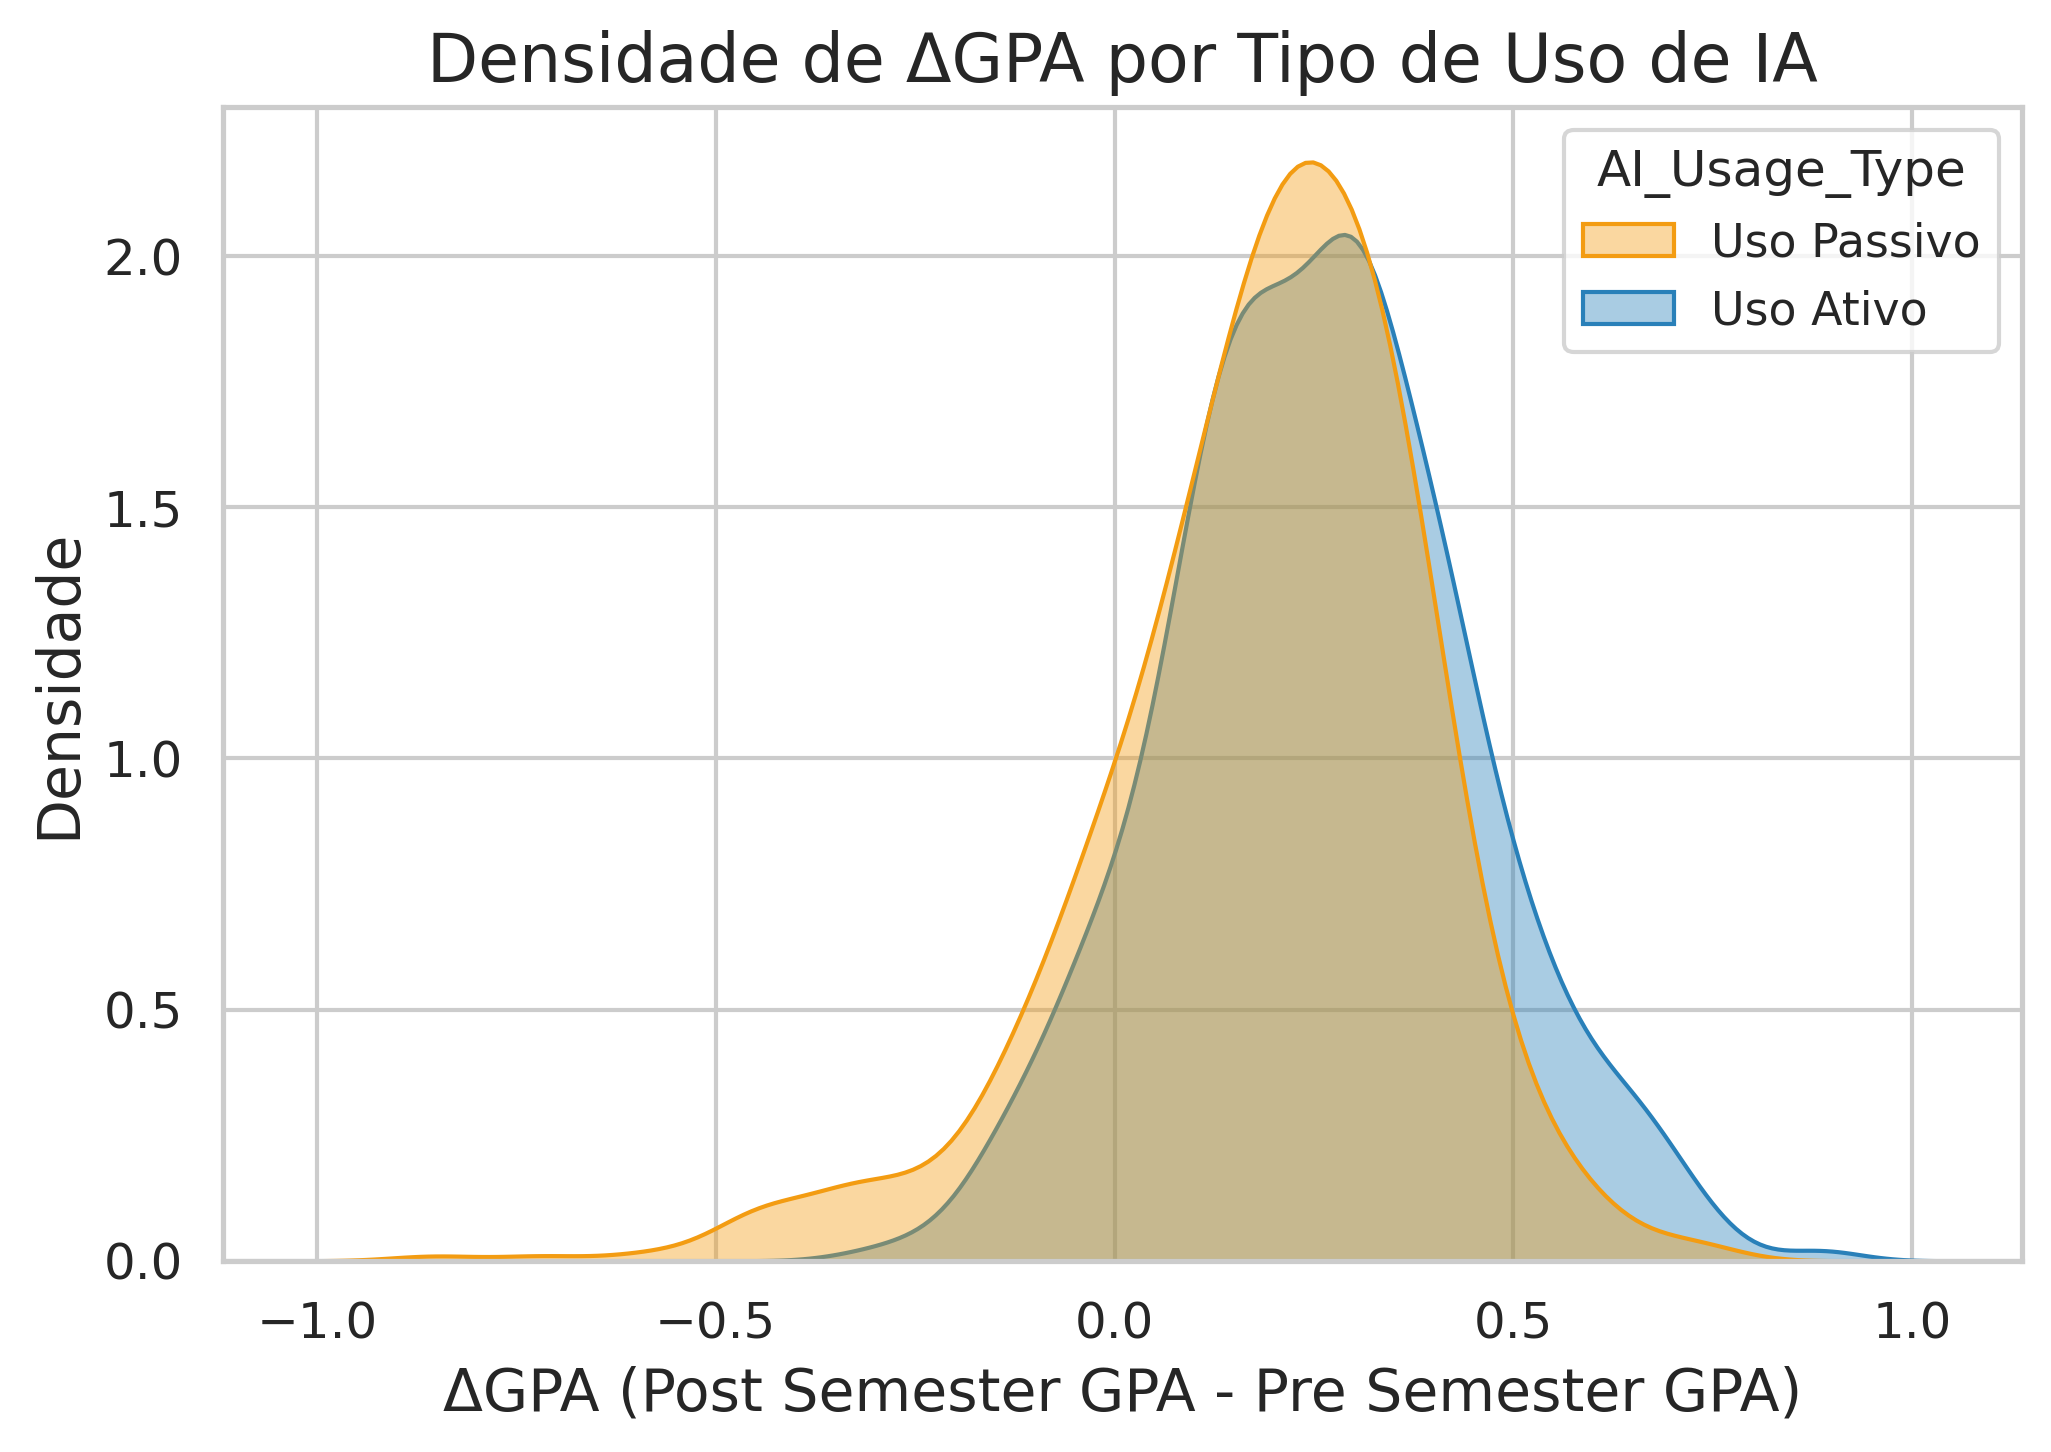

/tmp/ipykernel_1118/1538028318.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=matched_df, x='AI_Usage_Type', y='Delta_GPA',


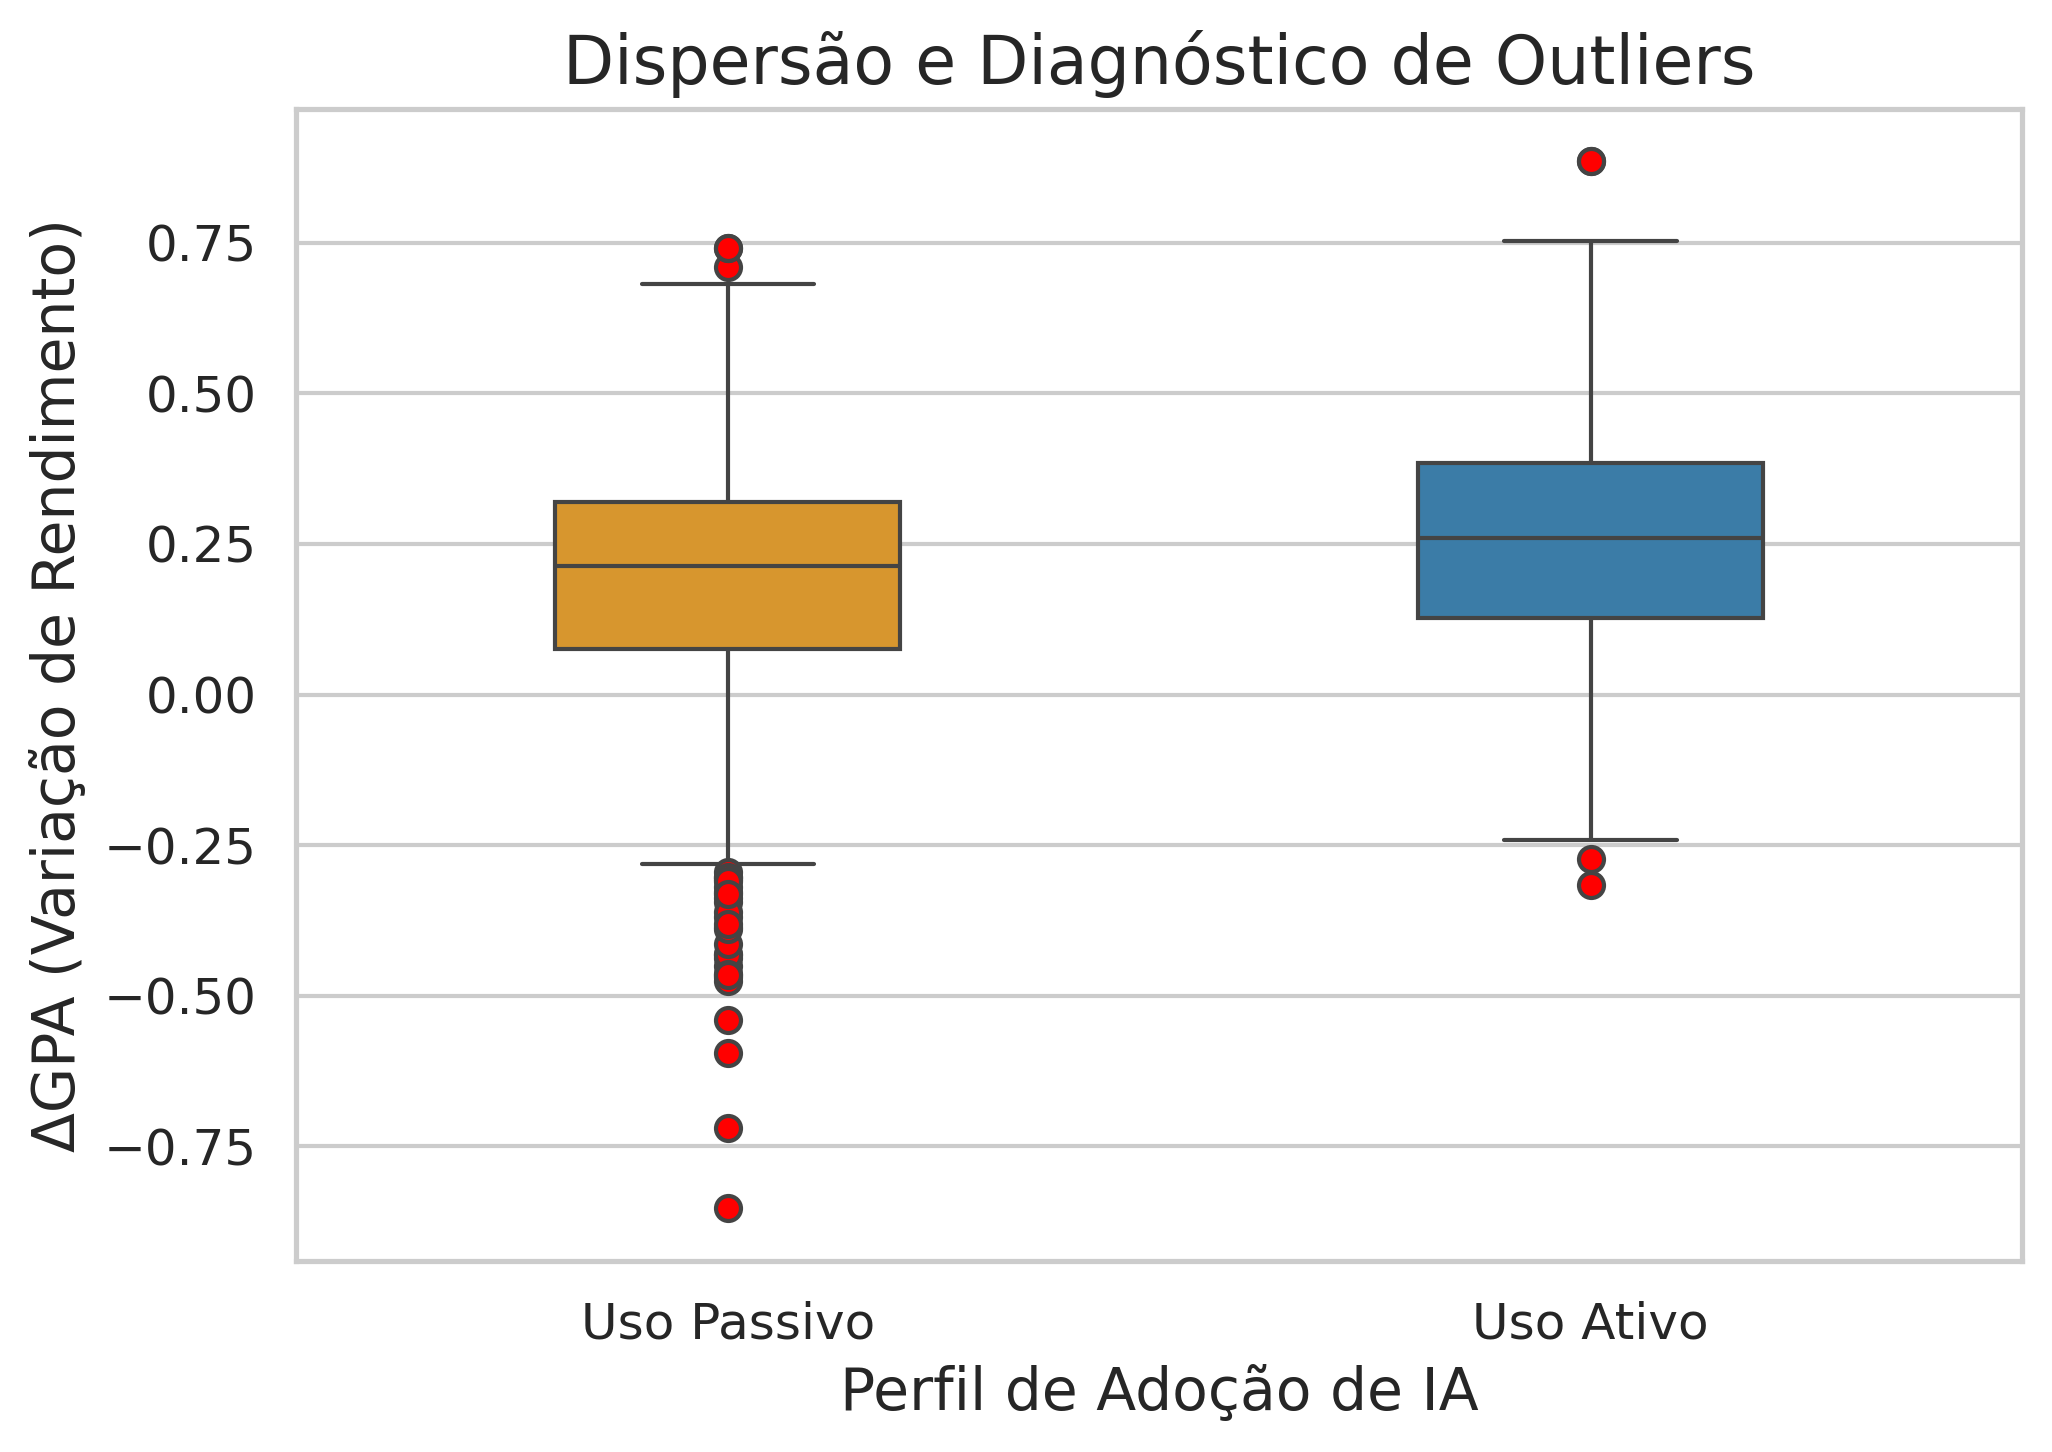


=== Análise concluída com sucesso! Os gráficos foram salvos em alta resolução. ===


In [ ]:
# ------------------------------------------------------------------------------
# 5. SLIDES 10 E 11: DISTRIBUIÇÃO KDE DO DELTA GPA E BOXPLOTS COM OUTLIERS
# ------------------------------------------------------------------------------
print("\n=== [5/5] Slides 10 e 11: Densidade do ΔGPA e Boxplots de Dispersão ===")

# Slide 10: KDE da Variável de Resposta (ΔGPA)
fig1, ax1 = plt.subplots(figsize=(7, 5), dpi=300)
sns.kdeplot(data=matched_df, x='Delta_GPA', hue='AI_Usage_Type', fill=True,
            palette={'Uso Ativo': '#2980b9', 'Uso Passivo': '#f39c12'}, ax=ax1, common_norm=False, alpha=0.4)
ax1.set_xlabel('ΔGPA (Post Semester GPA - Pre Semester GPA)')
ax1.set_ylabel('Densidade')
ax1.set_title('Densidade de ΔGPA por Tipo de Uso de IA')
plt.tight_layout()
plt.savefig('slide10_delta_gpa_kde.png', dpi=300)
plt.show()

# Slide 11: Boxplots e Outliers
fig2, ax2 = plt.subplots(figsize=(7, 5), dpi=300)
sns.boxplot(data=matched_df, x='AI_Usage_Type', y='Delta_GPA',
            palette={'Uso Ativo': '#2980b9', 'Uso Passivo': '#f39c12'}, ax=ax2, width=0.4,
            flierprops=dict(marker='o', markerfacecolor='r', markersize=6, linestyle='none'))
ax2.set_xlabel('Perfil de Adoção de IA')
ax2.set_ylabel('ΔGPA (Variação de Rendimento)')
ax2.set_title('Dispersão e Diagnóstico de Outliers')
plt.tight_layout()
plt.savefig('slide11_delta_gpa_boxplot.png', dpi=300)
plt.show()

print("\n=== Análise concluída com sucesso! Os gráficos foram salvos em alta resolução. ===")

### 📊 Planejamento de Experimentos Fatorial $2^3$

Um design fatorial $2^3$ avalia o efeito de **3 fatores** (vamos chamá-los de **A**, **B** e **C**), cada um operando em **2 níveis**:
* **Nível Baixo (represented por $-1$ ou $-$)**
* **Nível Alto (representado por $+1$ ou $+$)**

#### Exemplo Prático Aplicado ao Projeto:
* **Fator A (Uso de IA):** Uso Ativo ($-1$) vs. Uso Passivo ($+1$)
* **Fator B (Ansiedade):** Baixa Ansiedade ($-1$) vs. Alta Ansiedade ($+1$)
* **Fator C (Horas de Estudo):** Poucas Horas ($-1$) vs. Muitas Horas ($+1$)

---

### Matriz de Ensaios (Padrão de Yates)

A tabela abaixo apresenta as **8 rodadas (runs)** experimentais necessárias para cobrir todas as combinações possíveis de tratamentos:

| Ensaio (Run) | Fator A (IA) | Fator B (Ansiedade) | Fator C (Estudo) | Notação de Yates | Resposta Esperada ($Y = \Delta\text{GPA}$) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **1** | $-1$ | $-1$ | $-1$ | $(1)$ | Medida observada $y_1$ |
| **2** | $+1$ | $-1$ | $-1$ | $a$ | Medida observada $y_2$ |
| **3** | $-1$ | $+1$ | $-1$ | $b$ | Medida observada $y_3$ |
| **4** | $+1$ | $+1$ | $-1$ | $ab$ | Medida observada $y_4$ |
| **5** | $-1$ | $-1$ | $+1$ | $c$ | Medida observada $y_5$ |
| **6** | $+1$ | $-1$ | $+1$ | $ac$ | Medida observada $y_6$ |
| **7** | $-1$ | $+1$ | $+1$ | $bc$ | Medida observada $y_7$ |
| **8** | $+1$ | $+1$ | $+1$ | $abc$ | Medida observada $y_8$ |

#### Análise de Efeitos Principais e Interações:
Com essa estrutura, além de medir o impacto isolado de cada fator, você consegue calcular matematicamente a **interação conjunta** entre as variáveis, como por exemplo se o efeito de usar IA de forma passiva (Fator A) é potencializado ou mitigado quando o aluno estuda muitas horas (Fator C).

### 📈 Definição Prática dos Níveis Baixo ($-1$) e Alto ($+1$)

Para variáveis numéricas contínuas ou discretas multiclasses, a definição dos níveis não deve ser arbitrária. Duas abordagens comuns e estatisticamente robustas são:

1. **Critério dos Quartis (Mais recomendado para contraste extremo):**
   * **Nível Baixo ($-1$):** 1º Quartil (Percentil 25) — garante que estamos olhando para valores genuinamente baixos.
   * **Nível Alto ($+1$):** 3º Quartil (Percentil 75) — garante que estamos olhando para valores genuinamente altos.

2. **Critério da Mediana (Mais recomendado para dividir todo o dataset ao meio):**
   * **Nível Baixo ($-1$):** Abaixo ou igual à Mediana.
   * **Nível Alto ($+1$):** Acima da Mediana.

Vamos rodar o código abaixo para extrair esses valores limite exatos diretamente do seu conjunto de dados de alunos **STEM Junior**.

In [ ]:
# Calculando os limites recomendados para o Experimento 2³ usando Quartis (Q1 e Q3)
if 'df_filtered' in globals():
    # Ansiedade
    ansiedade_q1 = df_filtered['Anxiety_Level_During_Exams'].quantile(0.25)
    ansiedade_q3 = df_filtered['Anxiety_Level_During_Exams'].quantile(0.75)

    # Horas de Estudo
    estudo_q1 = df_filtered['Traditional_Study_Hours'].quantile(0.25)
    estudo_q3 = df_filtered['Traditional_Study_Hours'].quantile(0.75)

    print("=== Sugestão de Parametrização para o Experimento Fatorial 2³ ===\n")
    print(f"Fator B - Nível de Ansiedade Durante Exames:")
    print(f"  • Nível Baixo (-1): <= {ansiedade_q1:.2f} (representando baixa ansiedade)")
    print(f"  • Nível Alto  (+1): >= {ansiedade_q3:.2f} (representando alta ansiedade)\n")

    print(f"Fator C - Horas de Estudo Tradicional:")
    print(f"  • Nível Baixo (-1): <= {estudo_q1:.2f} horas/semana (pouco estudo)")
    print(f"  • Nível Alto  (+1): >= {estudo_q3:.2f} horas/semana (muito estudo)")
else:
    print("Execute as células iniciais para carregar 'df_filtered'.")

Execute as células iniciais para carregar 'df_filtered'.


In [ ]:
import numpy as np
import pandas as pd

# Verificar se df_filtered existe no workspace. Se não, rodar a filtragem básica.
if 'df_filtered' not in globals() or df_filtered.empty:
    try:
        df = pd.read_csv("ai_student_impact_dataset.csv")
    except FileNotFoundError:
        # Recriar simulação idêntica se o arquivo não estiver presente
        np.random.seed(42)
        n_samples = 50000
        df = pd.DataFrame({
            'Student_ID': np.arange(100001, 100001 + n_samples),
            'Pre_Semester_GPA': np.random.uniform(1.5, 4.0, n_samples),
            'Post_Semester_GPA': np.random.uniform(1.0, 4.0, n_samples),
            'Anxiety_Level_During_Exams': np.random.randint(1, 11, n_samples),
            'Traditional_Study_Hours': np.random.uniform(2, 30, n_samples),
            'Primary_Use_Case': np.random.choice(
                ['Copywriting/Drafting', 'Direct_Answer_Generation', 'Summarizing_Reading', 'Debugging/Troubleshooting', 'Ideation'],
                size=n_samples, p=[0.25, 0.25, 0.20, 0.15, 0.15]
            ),
            'Major_Category': np.random.choice(['STEM', 'Humanities', 'Business', 'Arts'], size=n_samples, p=[0.4, 0.2, 0.3, 0.1]),
            'Year_of_Study': np.random.choice(['Freshman', 'Sophomore', 'Junior', 'Senior'], size=n_samples, p=[0.25, 0.25, 0.25, 0.25])
        })
    df['Delta_GPA'] = df['Post_Semester_GPA'] - df['Pre_Semester_GPA']
    df['Treatment_Passive_AI'] = df['Primary_Use_Case'].isin(['Copywriting/Drafting', 'Direct_Answer_Generation']).astype(int)
    df_filtered = df[(df['Major_Category'] == 'STEM') & (df['Year_of_Study'] == 'Junior')].copy()

# 1. Definir limites por quartis nos dados reais do STEM Junior
q1_anx = df_filtered['Anxiety_Level_During_Exams'].quantile(0.25)
q3_anx = df_filtered['Anxiety_Level_During_Exams'].quantile(0.75)

q1_std = df_filtered['Traditional_Study_Hours'].quantile(0.25)
q3_std = df_filtered['Traditional_Study_Hours'].quantile(0.75)

# 2. Codificar os fatores A, B e C como -1 e +1
# Para evitar perda excessiva de dados ao usar estritamente os quartis extremos,
# vamos classificar abaixo da mediana como -1 e acima como +1 para manter o poder estatístico.
med_anx = df_filtered['Anxiety_Level_During_Exams'].median()
med_std = df_filtered['Traditional_Study_Hours'].median()

df_factorial = df_filtered.copy()
df_factorial['Factor_A'] = df_factorial['Treatment_Passive_AI'].map({0: -1, 1: 1})
df_factorial['Factor_B'] = np.where(df_factorial['Anxiety_Level_During_Exams'] > med_anx, 1, -1)
df_factorial['Factor_C'] = np.where(df_factorial['Traditional_Study_Hours'] > med_std, 1, -1)

# 3. Calcular a média de Y (Delta_GPA) para cada uma das 8 células
group_means = df_factorial.groupby(['Factor_A', 'Factor_B', 'Factor_C'])['Delta_GPA'].mean().to_dict()

# Garantir que todas as 8 combinações existem
y_runs = {}
for a in [-1, 1]:
    for b in [-1, 1]:
        for c in [-1, 1]:
            y_runs[(a, b, c)] = group_means.get((a, b, c), 0.0)

# 4. Cálculo dos Efeitos usando contraste clássico de Yates
# Cada efeito é a média das respostas com sinal positivo menos a média das respostas com sinal negativo.
def calculate_effect(sign_dict):
    pos_sum = sum(y_runs[comb] for comb, sign in sign_dict.items() if sign == 1)
    neg_sum = sum(y_runs[comb] for comb, sign in sign_dict.items() if sign == -1)
    return (pos_sum - neg_sum) / 4

# Definição dos sinais para cada combinação (A, B, C)
comb_keys = [(a, b, c) for a in [-1, 1] for b in [-1, 1] for c in [-1, 1]]

signs_A = {comb: comb[0] for comb in comb_keys}
signs_B = {comb: comb[1] for comb in comb_keys}
signs_C = {comb: comb[2] for comb in comb_keys}

signs_AB = {comb: comb[0] * comb[1] for comb in comb_keys}
signs_AC = {comb: comb[0] * comb[2] for comb in comb_keys}
signs_BC = {comb: comb[1] * comb[2] for comb in comb_keys}

signs_ABC = {comb: comb[0] * comb[1] * comb[2] for comb in comb_keys}

# Execução dos cálculos
effect_A = calculate_effect(signs_A)
effect_B = calculate_effect(signs_B)
effect_C = calculate_effect(signs_C)
effect_AB = calculate_effect(signs_AB)
effect_AC = calculate_effect(signs_AC)
effect_BC = calculate_effect(signs_BC)
effect_ABC = calculate_effect(signs_ABC)

# Exibir os resultados de forma estruturada
print("=== RESULTADOS DOS EFEITOS DO EXPERIMENTO FATORIAL 2³ ===\n")
print(f"Efeito Principal A (Uso de IA - Ativo vs Passivo):    {effect_A:+.6f}")
print(f"Efeito Principal B (Nível de Ansiedade):              {effect_B:+.6f}")
print(f"Efeito Principal C (Horas de Estudo Tradicional):      {effect_C:+.6f}")
print("-" * 60)
print(f"Interação de Duas Vias AB (IA x Ansiedade):            {effect_AB:+.6f}")
print(f"Interação de Duas Vias AC (IA x Estudo):               {effect_AC:+.6f}")
print(f"Interação de Duas Vias BC (Ansiedade x Estudo):        {effect_BC:+.6f}")
print("-" * 60)
print(f"Interação de Três Vias ABC:                            {effect_ABC:+.6f}")


=== RESULTADOS DOS EFEITOS DO EXPERIMENTO FATORIAL 2³ ===

Efeito Principal A (Uso de IA - Ativo vs Passivo):    -0.045272
Efeito Principal B (Nível de Ansiedade):              +0.000113
Efeito Principal C (Horas de Estudo Tradicional):      +0.004001
------------------------------------------------------------
Interação de Duas Vias AB (IA x Ansiedade):            -0.101617
Interação de Duas Vias AC (IA x Estudo):               +0.001853
Interação de Duas Vias BC (Ansiedade x Estudo):        -0.001944
------------------------------------------------------------
Interação de Três Vias ABC:                            -0.032321
